In [1]:
#Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import sys
import os
import seaborn as sns
from sklearn.decomposition import PCA
from joblib import dump, load
from collections import defaultdict
from matplotlib.gridspec import GridSpec


# Add the 'src' directory to the system path
src_dir = os.path.abspath(os.path.join(os.getcwd(), "..", "src"))
sys.path.insert(0, src_dir)

#import the module
import standardised_pipeline_utils
import corr_utils
from scipy.stats import skew, kurtosis, ks_2samp
from sklearn.metrics import silhouette_samples, silhouette_score





## Datasets

In [2]:
pearson = load('data/full_pearson100.joblib')
pearson


,A1BG,A1BG-AS1,A1CF,A2M,A2M-AS1,A2ML1,A2ML1-AS1,A2ML1-AS2,A2MP1,A3GALT2,...,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11AP1,ZYG11B,ZYX,ZZEF1,ZZZ3
proteins,,,,,,,,,,,,,,,,,,,,,
A2M,0.246571,0.207437,0.000000,0.365397,0.000000,0.000000,0.0,0.0,0.0,0.166604,...,0.000000,0.000000,0.000000,0.000000,0.0,0.070655,0.206545,0.176568,0.000000,0.000000
AAAS,0.000000,0.000000,0.000000,0.000000,0.089634,0.000000,0.0,0.0,0.0,0.000000,...,-0.098537,0.000000,0.000000,0.000000,0.0,-0.074209,0.000000,0.126028,-0.140422,0.124015
AACS,0.000000,0.000000,0.086278,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000
AAGAB,0.095826,0.106925,0.000000,0.000000,0.000000,-0.147446,0.0,0.0,0.0,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,-0.108280,0.235286,0.000000
AAK1,0.141985,0.129458,-0.118349,0.098589,0.094037,-0.076360,0.0,0.0,0.0,0.094948,...,0.148686,0.104587,0.101981,0.000000,0.0,0.000000,0.275717,0.300802,0.000000,0.118403
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZRANB2,0.000000,0.000000,-0.104882,0.000000,-0.075800,0.000000,0.0,0.0,0.0,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,-0.195975,0.000000,0.186568
ZW10,0.000000,0.000000,0.000000,0.000000,0.148775,0.000000,0.0,0.0,0.0,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.125551,0.000000,0.000000
ZWILCH,0.000000,0.000000,0.000000,0.000000,0.000000,-0.164620,0.0,0.0,0.0,0.000000,...,0.157618,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.157165,0.106069


In [3]:
transcriptomics_filtered = load('data/transcriptomics_kde_filtered.joblib')
transcriptomics_filtered

,A1BG,A1BG-AS1,A1CF,A2M,A2ML1,A4GALT,AAAS,AACS,AACSP1,AADAC,...,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3
Unnamed: 0,,,,,,,,,,,,,,,,,,,,,
MDAMB468_BREAST,2.689299,2.954196,0.014355,3.329124,0.443607,1.575312,5.311430,4.531069,0.056584,0.124328,...,4.139142,6.986752,2.192194,3.114367,4.250962,2.792855,3.250962,6.233811,3.512227,5.221490
SH4_SKIN,4.980025,3.583760,0.000000,8.405099,0.000000,0.111031,5.229972,4.095924,0.070389,0.014355,...,3.698218,6.113742,1.384050,2.659925,4.979111,0.014355,2.553361,6.644000,3.659925,4.249445
AU565_BREAST,2.518535,2.269033,0.014355,1.275007,2.451541,0.933573,6.011898,5.564378,1.618239,0.250962,...,4.235727,7.373909,0.632268,2.049631,3.471187,0.014355,2.794936,7.776828,3.814550,3.978196
KMRC1_KIDNEY,0.084064,0.070389,0.000000,0.137504,0.000000,2.903038,4.842476,3.357552,0.056584,0.124328,...,4.584361,6.704734,0.432959,1.021480,1.475085,0.485427,1.384050,5.510962,1.263034,3.416840
CAL51_BREAST,4.729553,2.807355,0.014355,0.575312,0.713696,3.751678,6.262847,3.874797,0.056584,0.070389,...,4.835924,7.356496,1.700440,2.424922,3.884598,0.084064,3.558268,6.812113,4.068671,4.939697
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
FADU_UPPER_AERODIGESTIVE_TRACT,0.070389,0.389567,0.028569,0.028569,0.263034,4.168321,5.244887,5.409391,0.189034,2.446256,...,4.865919,7.543882,0.014355,0.028569,3.807355,0.790772,3.247928,5.279471,4.277241,5.158660
KP4_PANCREAS,0.389567,0.632268,0.042644,0.367371,0.150560,2.163499,6.280585,4.335569,0.014355,4.980939,...,5.210233,6.656067,2.137504,2.558268,3.754888,0.042644,2.912650,6.915401,3.799087,4.475085
MONOMAC6_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,3.945795,2.185867,0.014355,0.000000,0.070389,0.042644,5.667608,3.218781,0.056584,0.000000,...,4.143230,7.929318,1.137504,1.835924,4.955127,0.056584,2.107688,5.816856,3.693766,5.030777


In [4]:
#Remove genes filtered out in the filtering procedure
pearson = pearson[transcriptomics_filtered.columns]
pearson

,A1BG,A1BG-AS1,A1CF,A2M,A2ML1,A4GALT,AAAS,AACS,AACSP1,AADAC,...,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3
proteins,,,,,,,,,,,,,,,,,,,,,
A2M,0.246571,0.207437,0.000000,0.365397,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.124962,0.000000,0.000000,0.000000,0.000000,0.0,0.206545,0.176568,0.000000,0.000000
AAAS,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.160298,0.0,0.000000,...,-0.078537,-0.098537,0.000000,0.000000,0.000000,0.0,0.000000,0.126028,-0.140422,0.124015
AACS,0.000000,0.000000,0.086278,0.000000,0.000000,-0.113664,0.000000,0.470513,0.0,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000
AAGAB,0.095826,0.106925,0.000000,0.000000,-0.147446,-0.121553,0.168963,0.000000,0.0,0.000000,...,0.191555,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,-0.108280,0.235286,0.000000
AAK1,0.141985,0.129458,-0.118349,0.098589,-0.076360,0.000000,0.000000,0.000000,0.0,-0.133701,...,0.092193,0.148686,0.104587,0.101981,0.000000,0.0,0.275717,0.300802,0.000000,0.118403
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZRANB2,0.000000,0.000000,-0.104882,0.000000,0.000000,-0.156288,0.190009,0.000000,0.0,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,-0.195975,0.000000,0.186568
ZW10,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.125551,0.000000,0.000000
ZWILCH,0.000000,0.000000,0.000000,0.000000,-0.164620,-0.119140,0.155437,0.000000,0.0,0.000000,...,0.222471,0.157618,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.157165,0.106069


## Cluster Overlap

read all clusters

In [5]:
# Read all cluster files from the three directories
pg_clusters = corr_utils.read_cluster_files('results/clusters_pg')
pp_clusters = corr_utils.read_cluster_files('results/clusters_pp')
pe_clusters = corr_utils.read_cluster_files('results/clusters_pe')

# Get common k values across all methods
common_k_values = sorted(set(pg_clusters.keys()) & set(pp_clusters.keys()) & set(pe_clusters.keys()))

if not common_k_values:
    print("No common k values found across all three clustering methods!")
else:
    print(f"Common k values found: {common_k_values}")
    
    # Create a directory to store overlap results if it doesn't exist
    import os
    results_dir = 'results/overlap_analysis'
    os.makedirs(results_dir, exist_ok=True)
    
    # For each common k value, compute and save overlap between all pairs of methods
    for k in common_k_values:
        print(f"\nAnalyzing clusters for k={k}...")
        
        # Get the corresponding dataframes for this k value
        pg_df = pg_clusters[k]
        pp_df = pp_clusters[k]
        pe_df = pe_clusters[k]
        
        # Compute overlap between PG and PP
        pg_pp_overlap_count, pg_pp_overlap_pct, pg_pp_contingency = corr_utils.compute_overlap(
            pg_df, pp_df, 
            df1_name=f"PG_k{k}", df2_name=f"PP_k{k}",
            output_file=f"{results_dir}/PG_PP_k{k}_overlap.csv"
        )
        
        # Compute overlap between PG and PE
        pg_pe_overlap_count, pg_pe_overlap_pct, pg_pe_contingency = corr_utils.compute_overlap(
            pg_df, pe_df, 
            df1_name=f"PG_k{k}", df2_name=f"PE_k{k}",
            output_file=f"{results_dir}/PG_PE_k{k}_overlap.csv"
        )
        
        # Compute overlap between PP and PE
        pp_pe_overlap_count, pp_pe_overlap_pct, pp_pe_contingency = corr_utils.compute_overlap(
            pp_df, pe_df, 
            df1_name=f"PP_k{k}", df2_name=f"PE_k{k}",
            output_file=f"{results_dir}/PP_PE_k{k}_overlap.csv"
        )
        
        # Print summary for this k value
        print(f"Overlap analysis for k={k}:")
        print(f"  PG vs PP: {pg_pp_overlap_count} proteins ({pg_pp_overlap_pct:.2f}%)")
        print(f"  PG vs PE: {pg_pe_overlap_count} proteins ({pg_pe_overlap_pct:.2f}%)")
        print(f"  PP vs PE: {pp_pe_overlap_count} proteins ({pp_pe_overlap_pct:.2f}%)")
        
        # Save contingency tables to CSV files
        pg_pp_contingency.to_csv(f"{results_dir}/PG_PP_k{k}_contingency.csv")
        pg_pe_contingency.to_csv(f"{results_dir}/PG_PE_k{k}_contingency.csv")
        pp_pe_contingency.to_csv(f"{results_dir}/PP_PE_k{k}_contingency.csv")
        
    # Create a summary dataframe with overlap percentages for each k value
    import pandas as pd
    summary_data = []
    
    for k in common_k_values:
        # Get the corresponding dataframes for this k value
        pg_df = pg_clusters[k]
        pp_df = pp_clusters[k]
        pe_df = pe_clusters[k]
        
        # Compute overlap counts and percentages
        pg_pp_overlap_count, pg_pp_overlap_pct, _ = corr_utils.compute_overlap(pg_df, pp_df, output_file=os.devnull)
        pg_pe_overlap_count, pg_pe_overlap_pct, _ = corr_utils.compute_overlap(pg_df, pe_df, output_file=os.devnull)
        pp_pe_overlap_count, pp_pe_overlap_pct, _ = corr_utils.compute_overlap(pp_df, pe_df, output_file=os.devnull)
        
        summary_data.append({
            'k': k,
            'PG_PP_overlap_count': pg_pp_overlap_count,
            'PG_PP_overlap_pct': pg_pp_overlap_pct,
            'PG_PE_overlap_count': pg_pe_overlap_count,
            'PG_PE_overlap_pct': pg_pe_overlap_pct,
            'PP_PE_overlap_count': pp_pe_overlap_count,
            'PP_PE_overlap_pct': pp_pe_overlap_pct
        })
    
    # Create and save summary dataframe
    summary_df = pd.DataFrame(summary_data)
    summary_df.to_csv("results/overlap_summary.csv", index=False)
    print(f"\nOverlap summary has been saved to results/overlap_summary.csv")



Common k values found: [2, 3, 4, 5, 6, 7]

Analyzing clusters for k=2...
Overlap analysis for k=2:
  PG vs PP: 3029 proteins (59.24%)
  PG vs PE: 3303 proteins (64.60%)
  PP vs PE: 4413 proteins (86.31%)

Analyzing clusters for k=3...
Overlap analysis for k=3:
  PG vs PP: 2977 proteins (58.22%)
  PG vs PE: 2810 proteins (54.96%)
  PP vs PE: 3958 proteins (77.41%)

Analyzing clusters for k=4...
Overlap analysis for k=4:
  PG vs PP: 3115 proteins (60.92%)
  PG vs PE: 3175 proteins (62.10%)
  PP vs PE: 3810 proteins (74.52%)

Analyzing clusters for k=5...
Overlap analysis for k=5:
  PG vs PP: 3458 proteins (67.63%)
  PG vs PE: 3432 proteins (67.12%)
  PP vs PE: 3630 proteins (71.00%)

Analyzing clusters for k=6...
Overlap analysis for k=6:
  PG vs PP: 3149 proteins (61.59%)
  PG vs PE: 3353 proteins (65.58%)
  PP vs PE: 3567 proteins (69.76%)

Analyzing clusters for k=7...
Overlap analysis for k=7:
  PG vs PP: 2555 proteins (49.97%)
  PG vs PE: 2983 proteins (58.34%)
  PP vs PE: 3097 prot

compute overlap

In [6]:
# Read all cluster files from the three directories
pg_clusters = corr_utils.read_cluster_files('results/clusters_pg')
pp_clusters = corr_utils.read_cluster_files('results/clusters_pp')
pe_clusters = corr_utils.read_cluster_files('results/clusters_pe')

# Get common k values across all methods
common_k_values = sorted(set(pg_clusters.keys()) & set(pp_clusters.keys()) & set(pe_clusters.keys()))

if not common_k_values:
    print("No common k values found across all three clustering methods!")
else:
    print(f"Common k values found: {common_k_values}")
    
    # Create a directory to store overlap results if it doesn't exist
    import os
    results_dir = 'results'
    os.makedirs(results_dir, exist_ok=True)
    
    # Store results for all k values
    results = {}
    
    # For each k value, compute overlap statistics
    for k in common_k_values:
        pg_df = pg_clusters[k]
        pp_df = pp_clusters[k]
        pe_df = pe_clusters[k]
        
        # Calculate pairwise overlaps with new compute_overlap function
        pg_pp_count, pg_pp_overlap, pg_pp_contingency = corr_utils.compute_overlap(
            pg_df, pp_df,
            df1_name=f"PG_k{k}", df2_name=f"PP_k{k}",
            output_file=f"{results_dir}/PG_PP_k{k}_overlap.csv"
        )
        
        pp_pe_count, pp_pe_overlap, pp_pe_contingency = corr_utils.compute_overlap(
            pp_df, pe_df,
            df1_name=f"PP_k{k}", df2_name=f"PE_k{k}",
            output_file=f"{results_dir}/PP_PE_k{k}_overlap.csv"
        )
        
        pg_pe_count, pg_pe_overlap, pg_pe_contingency = corr_utils.compute_overlap(
            pg_df, pe_df,
            df1_name=f"PG_k{k}", df2_name=f"PE_k{k}",
            output_file=f"{results_dir}/PG_PE_k{k}_overlap.csv"
        )
        
        # Calculate consensus across all three methods
        consensus_stats = corr_utils.compute_consensus(pg_df, pp_df, pe_df)
        
        # Store results
        results[k] = {
            'pg_pp_count': pg_pp_count,
            'pg_pp_overlap': pg_pp_overlap,
            'pp_pe_count': pp_pe_count,
            'pp_pe_overlap': pp_pe_overlap,
            'pg_pe_count': pg_pe_count,
            'pg_pe_overlap': pg_pe_overlap,
            'consensus_stats': consensus_stats,
            'contingency_pg_pp': pg_pp_contingency,
            'contingency_pp_pe': pp_pe_contingency,
            'contingency_pg_pe': pg_pe_contingency
        }
    

Common k values found: [2, 3, 4, 5, 6, 7]


In [7]:

# Create summary dataframe with overlap statistics
summary_data = []
for k in common_k_values:
    summary_data.append({
        'k': k,
        'PG_PP_count': results[k]['pg_pp_count'],
        'PG_PP_overlap': results[k]['pg_pp_overlap'],
        'PP_PE_count': results[k]['pp_pe_count'],
        'PP_PE_overlap': results[k]['pp_pe_overlap'],
        'PG_PE_count': results[k]['pg_pe_count'],
        'PG_PE_overlap': results[k]['pg_pe_overlap'],
        'Full_consensus': results[k]['consensus_stats']['all_consensus']
    })

# Create and save summary dataframe
summary_df = pd.DataFrame(summary_data)
summary_df.to_csv(f"{results_dir}/overlap_summary.csv", index=False)
print(f"\nOverlap summary has been saved to {results_dir}/overlap_summary.csv")

# Visualize results
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from matplotlib.gridspec import GridSpec

# Create a grid of plots (4 grids in total)
for k in common_k_values:
    # Create figure with subplots
    fig = plt.figure(figsize=(20, 15))
    gs = GridSpec(2, 2, figure=fig)
    
    # Grid 1: Individual cluster distributions
    ax1 = fig.add_subplot(gs[0, 0])
    
    # Calculate cluster distributions for each method
    pg_cluster_counts = pg_clusters[k]['Cluster'].value_counts().sort_index()
    pp_cluster_counts = pp_clusters[k]['Cluster'].value_counts().sort_index()
    pe_cluster_counts = pe_clusters[k]['Cluster'].value_counts().sort_index()
    
    # Normalize counts to percentages
    pg_cluster_pct = (pg_cluster_counts / pg_cluster_counts.sum()) * 100
    pp_cluster_pct = (pp_cluster_counts / pp_cluster_counts.sum()) * 100
    pe_cluster_pct = (pe_cluster_counts / pe_cluster_counts.sum()) * 100
    
    # Plotting
    bar_width = 0.25
    indices = np.arange(1, k + 1)
    
    ax1.bar(indices - bar_width, pg_cluster_pct, bar_width, label='PG')
    ax1.bar(indices, pp_cluster_pct, bar_width, label='PP')
    ax1.bar(indices + bar_width, pe_cluster_pct, bar_width, label='PE')
    
    ax1.set_xlabel('Cluster Number')
    ax1.set_ylabel('Percentage of Proteins')
    ax1.set_title(f'Cluster Distributions for k={k}')
    ax1.set_xticks(indices)
    ax1.legend()
    
    # Grid 2: PG vs PP pairwise comparison
    ax2 = fig.add_subplot(gs[0, 1])
    sns.heatmap(results[k]['contingency_pg_pp'], annot=True, cmap='viridis', fmt='d', ax=ax2)
    ax2.set_title(f'PG vs PP Clusters (Overlap: {results[k]["pg_pp_count"]} proteins, {results[k]["pg_pp_overlap"]:.2f}%)')
    ax2.set_xlabel('PP Clusters')
    ax2.set_ylabel('PG Clusters')
    
    # Grid 3: PP vs PE pairwise comparison
    ax3 = fig.add_subplot(gs[1, 0])
    sns.heatmap(results[k]['contingency_pp_pe'], annot=True, cmap='viridis', fmt='d', ax=ax3)
    ax3.set_title(f'PP vs PE Clusters (Overlap: {results[k]["pp_pe_count"]} proteins, {results[k]["pp_pe_overlap"]:.2f}%)')
    ax3.set_xlabel('PE Clusters')
    ax3.set_ylabel('PP Clusters')
    
    # Grid 4: PG vs PE pairwise comparison
    ax4 = fig.add_subplot(gs[1, 1])
    sns.heatmap(results[k]['contingency_pg_pe'], annot=True, cmap='viridis', fmt='d', ax=ax4)
    ax4.set_title(f'PG vs PE Clusters (Overlap: {results[k]["pg_pe_count"]} proteins, {results[k]["pg_pe_overlap"]:.2f}%)')
    ax4.set_xlabel('PE Clusters')
    ax4.set_ylabel('PG Clusters')
    
    plt.tight_layout()
    plt.savefig(f'{results_dir}/cluster_comparison_k{k}.png', dpi=300)
    plt.close()
    
    # Create an additional figure for the consensus visualization
    fig_consensus = plt.figure(figsize=(10, 8))
    consensus_stats = results[k]['consensus_stats']
    
    # Create a bar chart showing consensus percentages
    consensus_data = [
        consensus_stats['pg_pp_overlap'],
        consensus_stats['pp_pe_overlap'],
        consensus_stats['pg_pe_overlap'],
        consensus_stats['all_consensus']
    ]
    
    labels = ['PG-PP', 'PP-PE', 'PG-PE', 'All Three']
    
    plt.bar(labels, consensus_data)
    plt.ylabel('Percentage of Proteins')
    plt.title(f'Clustering Consensus (k={k})')
    plt.ylim(0, 100)
    
    # Add text with the actual percentages
    for i, v in enumerate(consensus_data):
        plt.text(i, v + 1, f'{v:.2f}%', ha='center')
    
    # Add annotation with total proteins and full consensus count
    plt.annotate(
        f'Total proteins: {consensus_stats["total_proteins"]}\n'
        f'Full consensus count: {consensus_stats["full_consensus_count"]} '
        f'({consensus_stats["all_consensus"]:.2f}%)',
        xy=(0.5, 0.9),
        xycoords='axes fraction',
        ha='center',
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.8)
    )
    
    plt.tight_layout()
    plt.savefig(f'{results_dir}/consensus_visualization_k{k}.png', dpi=300)
    plt.close()


Overlap summary has been saved to results/overlap_summary.csv


visualize results

In [8]:
# Visualize results
# Create a grid of plots (4 grids in total)
for k in common_k_values:
    # Create figure with subplots
    fig = plt.figure(figsize=(20, 15))
    gs = GridSpec(2, 2, figure=fig)
    
    # Grid 1: Individual cluster distributions
    ax1 = fig.add_subplot(gs[0, 0])
    
    # Calculate cluster distributions for each method
    pg_cluster_counts = pg_clusters[k]['Cluster'].value_counts().sort_index()
    pp_cluster_counts = pp_clusters[k]['Cluster'].value_counts().sort_index()
    pe_cluster_counts = pe_clusters[k]['Cluster'].value_counts().sort_index()
    
    # Normalize counts to percentages
    pg_cluster_pct = (pg_cluster_counts / pg_cluster_counts.sum()) * 100
    pp_cluster_pct = (pp_cluster_counts / pp_cluster_counts.sum()) * 100
    pe_cluster_pct = (pe_cluster_counts / pe_cluster_counts.sum()) * 100
    
    # Plotting
    bar_width = 0.25
    indices = np.arange(1, k + 1)
    
    ax1.bar(indices - bar_width, pg_cluster_pct, bar_width, label='PG')
    ax1.bar(indices, pp_cluster_pct, bar_width, label='PP')
    ax1.bar(indices + bar_width, pe_cluster_pct, bar_width, label='PE')
    
    ax1.set_xlabel('Cluster Number')
    ax1.set_ylabel('Percentage of Proteins')
    ax1.set_title(f'Cluster Distributions for k={k}')
    ax1.set_xticks(indices)
    ax1.legend()
    
    # Grid 2: PG vs PP pairwise comparison
    ax2 = fig.add_subplot(gs[0, 1])
    sns.heatmap(results[k]['contingency_pg_pp'], annot=True, cmap='viridis', fmt='d', ax=ax2)
    ax2.set_title(f'PG vs PP Clusters (Overlap: {results[k]["pg_pp_overlap"]:.2f}%)')
    ax2.set_xlabel('PP Clusters')
    ax2.set_ylabel('PG Clusters')
    
    # Grid 3: PP vs PE pairwise comparison
    ax3 = fig.add_subplot(gs[1, 0])
    sns.heatmap(results[k]['contingency_pp_pe'], annot=True, cmap='viridis', fmt='d', ax=ax3)
    ax3.set_title(f'PP vs PE Clusters (Overlap: {results[k]["pp_pe_overlap"]:.2f}%)')
    ax3.set_xlabel('PE Clusters')
    ax3.set_ylabel('PP Clusters')
    
    # Grid 4: PG vs PE pairwise comparison
    ax4 = fig.add_subplot(gs[1, 1])
    sns.heatmap(results[k]['contingency_pg_pe'], annot=True, cmap='viridis', fmt='d', ax=ax4)
    ax4.set_title(f'PG vs PE Clusters (Overlap: {results[k]["pg_pe_overlap"]:.2f}%)')
    ax4.set_xlabel('PE Clusters')
    ax4.set_ylabel('PG Clusters')
    
    plt.tight_layout()
    plt.savefig(f'cluster_comparison_k{k}.png', dpi=300)
    plt.close()
    
    # Create an additional figure for the consensus visualization
    fig_consensus = plt.figure(figsize=(10, 8))
    consensus_stats = results[k]['consensus_stats']
    
    # Create a bar chart showing consensus percentages
    consensus_data = [
        consensus_stats['pg_pp_overlap'],
        consensus_stats['pp_pe_overlap'],
        consensus_stats['pg_pe_overlap'],
        consensus_stats['all_consensus']
    ]
    
    labels = ['PG-PP', 'PP-PE', 'PG-PE', 'All Three']
    
    plt.bar(labels, consensus_data)
    plt.ylabel('Percentage of Proteins')
    plt.title(f'Clustering Consensus (k={k})')
    plt.ylim(0, 100)
    
    # Add text with the actual percentages
    for i, v in enumerate(consensus_data):
        plt.text(i, v + 1, f'{v:.2f}%', ha='center')
    
    # Add annotation with total proteins and full consensus count
    plt.annotate(
        f'Total proteins: {consensus_stats["total_proteins"]}\n'
        f'Full consensus count: {consensus_stats["full_consensus_count"]} '
        f'({consensus_stats["all_consensus"]:.2f}%)',
        xy=(0.9, 0.9),
        xycoords='axes fraction',
        ha='center',
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.8)
    )
    
    plt.tight_layout()
    plt.savefig(f'consensus_visualization_k{k}.png', dpi=300)
    plt.close()



print summary of results

In [9]:
# Print summary of results
print("\nSummary of Cluster Overlaps:")
print("=" * 50)
print(f"{'k':<5}{'PG-PP':<10}{'PP-PE':<10}{'PG-PE':<10}{'All Three':<15}")
print("-" * 50)

for k in sorted(results.keys()):
    pg_pp = results[k]['pg_pp_overlap']
    pp_pe = results[k]['pp_pe_overlap']
    pg_pe = results[k]['pg_pe_overlap']
    all_three = results[k]['consensus_stats']['all_consensus']
    
    print(f"{k:<5}{pg_pp:<10.2f}{pp_pe:<10.2f}{pg_pe:<10.2f}{all_three:<15.2f}")

print("\nDetailed Consensus Statistics:")
print("=" * 70)
for k in sorted(results.keys()):
    consensus = results[k]['consensus_stats']
    print(f"\nk = {k}:")
    print(f"  Total proteins analyzed: {consensus['total_proteins']}")
    print(f"  Full consensus count: {consensus['full_consensus_count']} proteins ({consensus['all_consensus']:.2f}%)")
    print(f"  PG-PP overlap: {consensus['pg_pp_overlap']:.2f}%")
    print(f"  PP-PE overlap: {consensus['pp_pe_overlap']:.2f}%")
    print(f"  PG-PE overlap: {consensus['pg_pe_overlap']:.2f}%")


Summary of Cluster Overlaps:
k    PG-PP     PP-PE     PG-PE     All Three      
--------------------------------------------------
2    59.24     86.31     64.60     53.84          
3    58.22     77.41     54.96     31.78          
4    60.92     74.52     62.10     15.41          
5    67.63     71.00     67.12     2.39           
6    61.59     69.76     65.58     2.39           
7    49.97     60.57     58.34     1.53           

Detailed Consensus Statistics:

k = 2:
  Total proteins analyzed: 5113
  Full consensus count: 2753 proteins (53.84%)
  PG-PP overlap: 59.24%
  PP-PE overlap: 86.31%
  PG-PE overlap: 62.14%

k = 3:
  Total proteins analyzed: 5113
  Full consensus count: 1625 proteins (31.78%)
  PG-PP overlap: 38.14%
  PP-PE overlap: 77.41%
  PG-PE overlap: 39.88%

k = 4:
  Total proteins analyzed: 5113
  Full consensus count: 788 proteins (15.41%)
  PG-PP overlap: 23.27%
  PP-PE overlap: 74.52%
  PG-PE overlap: 22.73%

k = 5:
  Total proteins analyzed: 5113
  Full consens

#### Save results

In [10]:
# Instead of visualization, create and save comprehensive results tables
results_data = []
for k in sorted(results.keys()):
    consensus = results[k]['consensus_stats']
    
    # Calculate average pairwise overlap
    avg_pairwise = (results[k]['pg_pp_overlap'] + 
                   results[k]['pp_pe_overlap'] + 
                   results[k]['pg_pe_overlap']) / 3
    
    # Add results to data
    results_data.append({
        'k': k,
        'Total_Proteins': consensus['total_proteins'],
        'PG_PP_Overlap': results[k]['pg_pp_overlap'],
        'PP_PE_Overlap': results[k]['pp_pe_overlap'],
        'PG_PE_Overlap': results[k]['pg_pe_overlap'],
        'Avg_Pairwise_Overlap': avg_pairwise,
        'Full_Consensus': consensus['all_consensus'],
        'Consensus_Count': consensus['full_consensus_count']
    })

# Create DataFrame from results
results_df = pd.DataFrame(results_data)

# Save the results to a CSV file
results_df.to_csv("cluster_overlap_results.csv", index=False)
print("\nCluster overlap results saved to 'cluster_overlap_results.csv'")

# Print summary table
print("\nSummary of Cluster Overlaps:")
print("=" * 80)
print(results_df.to_string(index=False, float_format=lambda x: f"{x:.2f}"))


Cluster overlap results saved to 'cluster_overlap_results.csv'

Summary of Cluster Overlaps:
 k  Total_Proteins  PG_PP_Overlap  PP_PE_Overlap  PG_PE_Overlap  Avg_Pairwise_Overlap  Full_Consensus  Consensus_Count
 2            5113          59.24          86.31          64.60                 70.05           53.84             2753
 3            5113          58.22          77.41          54.96                 63.53           31.78             1625
 4            5113          60.92          74.52          62.10                 65.85           15.41              788
 5            5113          67.63          71.00          67.12                 68.58            2.39              122
 6            5113          61.59          69.76          65.58                 65.64            2.39              122
 7            5113          49.97          60.57          58.34                 56.29            1.53               78


## Analysis 2 - 3

### 2 clusters


In [11]:
clusters = pd.read_csv('results/clusters_pg/protein_clusters_k2.csv')
clusters3 = pd.read_csv('results/clusters_pg/protein_clusters_k3.csv')

In [12]:
prot_c1 = clusters.loc[clusters.Cluster == 1, "Protein"]
prot_c2 = clusters.loc[clusters.Cluster == 2, "Protein"]

df_cluster1 = pearson.loc[pearson.index.intersection(prot_c1)]
df_cluster2 = pearson.loc[pearson.index.intersection(prot_c2)]

In [13]:
df_cluster1.describe()


,A1BG,A1BG-AS1,A1CF,A2M,A2ML1,A4GALT,AAAS,AACS,AACSP1,AADAC,...,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3
count,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000,...,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000
mean,0.052697,0.041527,0.001671,-0.035669,-0.056942,-0.130295,0.135283,-0.007268,0.004203,-0.051945,...,0.008123,0.046601,0.001413,0.018755,0.077743,0.007604,-0.007534,-0.129680,0.064359,0.016825
std,0.103388,0.093460,0.068581,0.068952,0.103703,0.098683,0.098201,0.058583,0.037471,0.074803,...,0.067396,0.090864,0.039743,0.052428,0.093185,0.060062,0.085200,0.110140,0.086929,0.066123
min,-0.394757,-0.419261,-0.257735,-0.305118,-0.319891,-0.388278,-0.220384,-0.250441,-0.207530,-0.264705,...,-0.259564,-0.276436,-0.197756,-0.187713,-0.147429,-0.239348,-0.371998,-0.382800,-0.192112,-0.253249
25%,0.000000,0.000000,0.000000,-0.094942,-0.149016,-0.205382,0.000000,0.000000,0.000000,-0.122120,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.211907,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,-0.144184,0.149406,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.151352,0.000000,0.000000
75%,0.137590,0.117899,0.000000,0.000000,0.000000,0.000000,0.209855,0.000000,0.000000,0.000000,...,0.000000,0.123822,0.000000,0.000000,0.160096,0.000000,0.000000,0.000000,0.142683,0.000000
max,0.331081,0.347560,0.620241,0.222556,0.239776,0.140660,0.434256,0.228584,0.172276,0.188117,...,0.282370,0.333329,0.226135,0.255212,0.419057,0.313880,0.276979,0.193424,0.386142,0.365429


In [14]:
df_cluster2.describe()

,A1BG,A1BG-AS1,A1CF,A2M,A2ML1,A4GALT,AAAS,AACS,AACSP1,AADAC,...,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3
count,3417.000000,3417.000000,3417.000000,3417.000000,3417.000000,3417.000000,3417.000000,3417.000000,3417.000000,3417.000000,...,3417.000000,3417.000000,3417.000000,3417.000000,3417.000000,3417.000000,3417.000000,3417.000000,3417.000000,3417.000000
mean,-0.024340,-0.017794,-0.006523,0.023690,0.014172,0.057664,-0.062467,0.010339,0.000215,0.026878,...,0.003930,-0.012715,0.005450,0.001571,-0.015335,0.004780,0.024285,0.080283,-0.025516,0.012170
std,0.128301,0.120221,0.084176,0.091136,0.107108,0.115315,0.110593,0.085612,0.039825,0.080878,...,0.072646,0.084495,0.043334,0.048808,0.082915,0.066900,0.100671,0.117853,0.087318,0.069591
min,-0.471511,-0.441072,-0.325459,-0.354596,-0.282106,-0.303208,-0.431696,-0.269874,-0.207714,-0.273304,...,-0.291625,-0.292748,-0.216721,-0.210611,-0.311360,-0.330242,-0.328854,-0.277035,-0.280359,-0.287883
25%,-0.109339,-0.095882,0.000000,0.000000,0.000000,0.000000,-0.148899,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.094334,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000,0.074769,0.096208,0.143700,0.000000,0.000000,0.000000,0.089207,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.173597,0.000000,0.000000
max,0.392804,0.409780,0.378436,0.395727,0.366103,0.462668,0.281534,0.470513,0.355469,0.350244,...,0.267605,0.270492,0.249703,0.235868,0.359242,0.357060,0.416357,0.685036,0.363437,0.286004


In [15]:

# compute the describe() tables
desc1 = df_cluster1.describe()
desc2 = df_cluster2.describe()

# pull out the "max" row and take its mean
avg_of_max1 = desc1.loc["max"].mean()
avg_of_max2 = desc2.loc["max"].mean()

# print the results
print(f"Average of per‑column max correlations (Cluster 1): {avg_of_max1:.4f}")
print(f"Average of per‑column max correlations (Cluster 2): {avg_of_max2:.4f}")


Average of per‑column max correlations (Cluster 1): 0.2950
Average of per‑column max correlations (Cluster 2): 0.3632


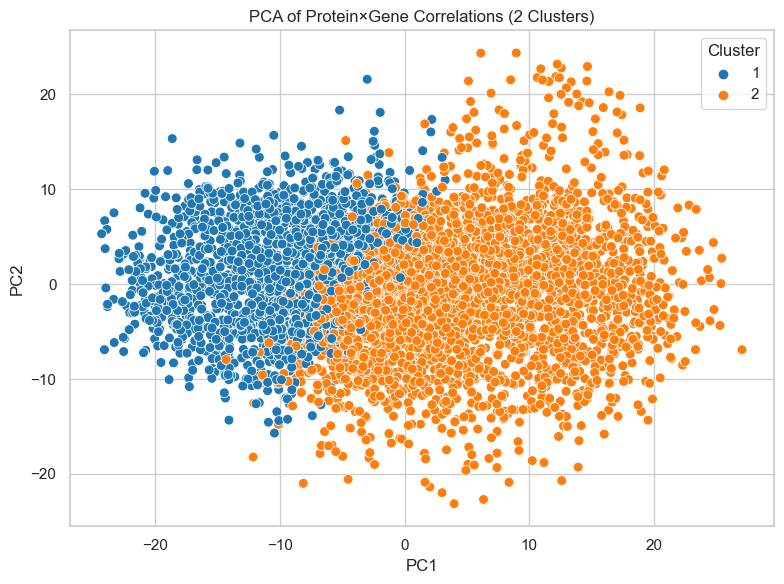

In [16]:

# --- Two clusters: single PCA scatter ---
# Inputs: pearson (protein×gene correlations), clusters (Protein→Cluster), df_cluster1, df_cluster2

# 1) PCA for 2 clusters
pca2 = PCA(n_components=2)
pcs2 = pca2.fit_transform(pearson.fillna(0))
df_pca2 = (
    pd.DataFrame(pcs2, index=pearson.index, columns=['PC1', 'PC2'])
      .join(clusters.set_index('Protein'))
      .reset_index()
)

# 2) Plot
sns.set_theme(style='whitegrid')
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df_pca2,
    x='PC1', y='PC2',
    hue='Cluster',
    palette='tab10',
    s=50
)
plt.title('PCA of Protein×Gene Correlations (2 Clusters)')
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()





Distributional analysis

In [17]:
# 2. Flatten and clean correlation values for distributional analysis
vals1 = df_cluster1.values.flatten()
vals2 = df_cluster2.values.flatten()
# Drop NaNs
vals1 = vals1[~np.isnan(vals1)]
vals2 = vals2[~np.isnan(vals2)]

# %% [code]
# 3. Summary statistics & percentiles
for name, vals in [('Cluster 1', vals1), ('Cluster 2', vals2)]:
    print(f"{name} Summary:")
    print(f"  Mean       = {np.mean(vals):.4f}")
    print(f"  Std Dev    = {np.std(vals, ddof=1):.4f}")
    print(f"  Median     = {np.median(vals):.4f}")
    print(f"  Skewness   = {skew(vals):.4f}")
    print(f"  Kurtosis   = {kurtosis(vals):.4f}")
    for p in [75, 90, 95]:
        print(f"  {p}th pct  = {np.percentile(vals, p):.4f}")
    print()

Cluster 1 Summary:
  Mean       = 0.0073
  Std Dev    = 0.1063
  Median     = 0.0000
  Skewness   = -0.0080
  Kurtosis   = 1.4265
  75th pct  = 0.0000
  90th pct  = 0.1529
  95th pct  = 0.1948

Cluster 2 Summary:
  Mean       = 0.0013
  Std Dev    = 0.0995
  Median     = 0.0000
  Skewness   = 0.1663
  Kurtosis   = 2.4958
  75th pct  = 0.0000
  90th pct  = 0.1337
  95th pct  = 0.1793



Correlation Thresholds

In [18]:
# 4. Compute cluster-specific correlation thresholds (e.g., top 10% strongest absolute correlations)
thr_pct = 90  # adjust percentile as needed
thr1 = np.percentile(np.abs(vals1), thr_pct)
thr2 = np.percentile(np.abs(vals2), thr_pct)
print(f"Threshold for top {thr_pct}% |r| in Cluster 1: {thr1:.4f}")
print(f"Threshold for top {thr_pct}% |r| in Cluster 2: {thr2:.4f}")

Threshold for top 90% |r| in Cluster 1: 0.1889
Threshold for top 90% |r| in Cluster 2: 0.1764


Cohesion & Separation (WSS, BSS, Silhouette)

In [19]:
# Combine clusters and labels
df_all = pd.concat([df_cluster1, df_cluster2])
labels = np.array([1]*df_cluster1.shape[0] + [2]*df_cluster2.shape[0])
X = df_all.values  # shape: (n_proteins, n_genes)

# Centroids
centroids = {
    1: np.nanmean(df_cluster1.values, axis=0),
    2: np.nanmean(df_cluster2.values, axis=0)
}
# Global centroid
global_cent = np.nanmean(X, axis=0)

# WSS per cluster
wss = {}
for k, df_k in zip([1, 2], [df_cluster1, df_cluster2]):
    diffs = df_k.values - centroids[k]
    wss[k] = np.nansum((diffs**2).sum(axis=1))
print(f"WSS Cluster 1: {wss[1]:.2f}")
print(f"WSS Cluster 2: {wss[2]:.2f}")

# BSS
bss = (df_cluster1.shape[0] * np.sum((centroids[1] - global_cent)**2)
       + df_cluster2.shape[0] * np.sum((centroids[2] - global_cent)**2))
print(f"Between-Cluster SS: {bss:.2f}")

WSS Cluster 1: 261167.53
WSS Cluster 2: 647894.94
Between-Cluster SS: 280808.95


In [20]:
# Silhouette
sil_vals = silhouette_samples(X, labels, metric='euclidean')
sil_mean = silhouette_score(X, labels, metric='euclidean')
sil_by_cluster = {k: sil_vals[labels==k].mean() for k in [1, 2]}
print(f"Mean Silhouette Score: {sil_mean:.4f}")
print(f"Cluster 1 Silhouette: {sil_by_cluster[1]:.4f}")
print(f"Cluster 2 Silhouette: {sil_by_cluster[2]:.4f}")

Mean Silhouette Score: 0.1989
Cluster 1 Silhouette: 0.2538
Cluster 2 Silhouette: 0.1716


Statistical Tests: KS Test & Cohen's d

In [21]:
def cohens_d(x, y):
    nx, ny = len(x), len(y)
    pooled_sd = np.sqrt(((nx-1)*np.var(x, ddof=1) + (ny-1)*np.var(y, ddof=1)) / (nx+ny-2))
    return (np.mean(x) - np.mean(y)) / pooled_sd

In [22]:
ks_stat, ks_p = ks_2samp(vals1, vals2)
cd = cohens_d(vals1, vals2)
print(f"KS Statistic: {ks_stat:.4f}, p-value: {ks_p:.4e}")
print(f"Cohen's d: {cd:.4f}")

# %% [code]
# 7. Cluster Centroids & Top Driver Genes
genes = df_cluster1.columns  # assume same columns for both
cent1 = centroids[1]
cent2 = centroids[2]

KS Statistic: 0.0431, p-value: 0.0000e+00
Cohen's d: 0.0592


In [23]:
# 7. Cluster Centroids & Top Driver Genes
genes = df_cluster1.columns  # assume same columns for both
cent1 = centroids[1]
cent2 = centroids[2]

# Select top-k by absolute centroid weight
k = 20
top1 = genes[np.argsort(np.abs(cent1))[-k:]][::-1]
top2 = genes[np.argsort(np.abs(cent2))[-k:]][::-1]

print(f"Top {k} driver genes in Cluster 1 based on centroid magnitude:")
print(top1.tolist(), '\n')
print(f"Top {k} driver genes in Cluster 2 based on centroid magnitude:")
print(top2.tolist())


Top 20 driver genes in Cluster 1 based on centroid magnitude:
['TNFRSF12A', 'ITGA3', 'PRSS23', 'MYOF', 'SDC4', 'MIR22HG', 'ANXA2P2', 'LMNA', 'RHOC', 'ANXA2', 'DDN', 'EPHA2', 'RHOH', 'IKZF1', 'WAS', 'AMOTL2', 'CAPN2', 'STRBP', 'RND3', 'AHNAK'] 

Top 20 driver genes in Cluster 2 based on centroid magnitude:
['IKZF1', 'LINC01215', 'IRAG2', 'CD79B', 'SASH3', 'WAS', 'TNFRSF12A', 'MAP4K1', 'AC023510.2', 'RHOH', 'PAX5', 'KLHL6', 'SH2D3C', 'CD53', 'AC004687.1', 'BTK', 'WDFY4', 'CD79A', 'NCKAP1L', 'LMNA']


find critical points

Exceed threshold in all proteins


Cluster 1 critical point:
  Percentile range: 61.22 - 62.24
  Avg genes per protein: 22614.00 → 8537.94
  Drop magnitude: 14076.06
  Correlation threshold value: 0.0000


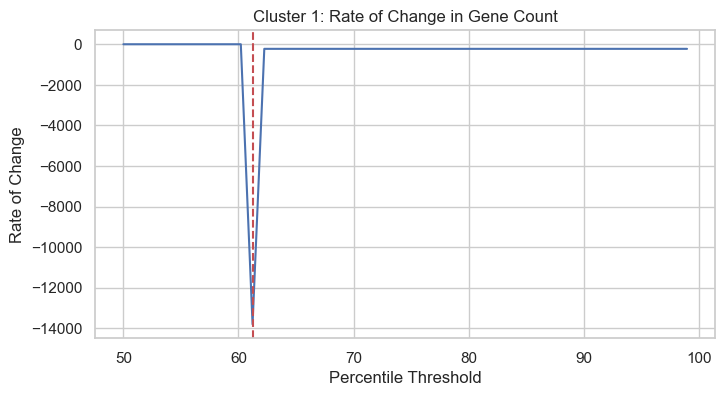


Cluster 2 critical point:
  Percentile range: 65.31 - 66.33
  Avg genes per protein: 22614.00 → 7614.92
  Drop magnitude: 14999.08
  Correlation threshold value: 0.0000


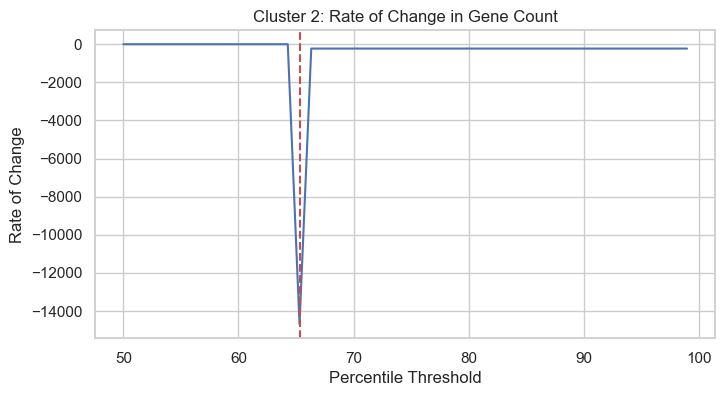

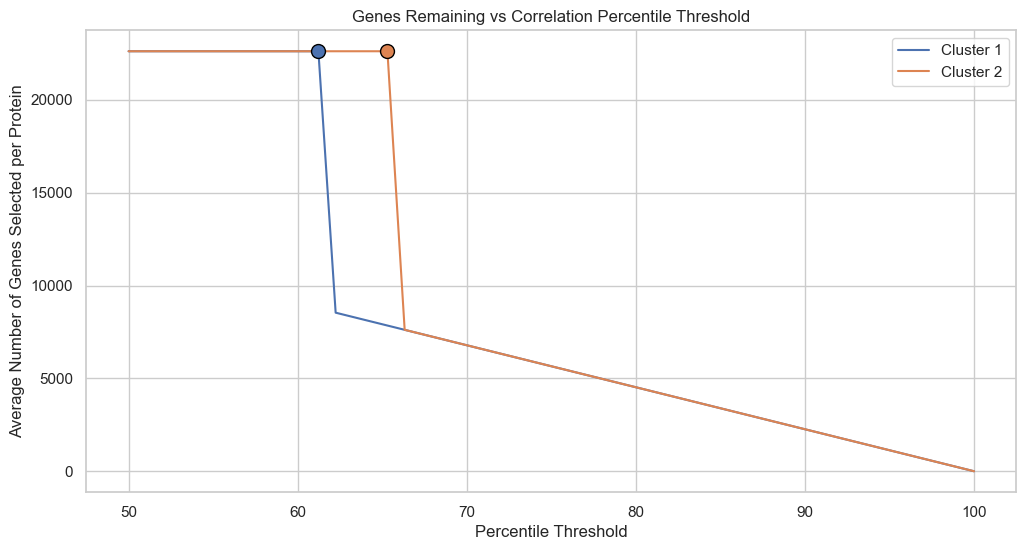

In [24]:
# --- Config ---
percentiles = np.linspace(50, 100, 50)

# Store results
thresholds = {}
gene_counts = {}

# First populate the thresholds and gene_counts dictionaries
for i, (name, df_cluster) in enumerate({"Cluster 1": df_cluster1, "Cluster 2": df_cluster2}.items()):
    vals = df_cluster.values.flatten()
    vals = vals[~np.isnan(vals)]
    
    thr_values = np.percentile(np.abs(vals), percentiles)
    thresholds[name] = thr_values
    
    counts = []
    for thr in thr_values:
        # Calculate average number of genes above threshold per protein (matching graph calculation)
        mask = (np.abs(df_cluster.values) >= thr)
        avg_genes_per_protein = mask.sum(axis=1).mean()
        counts.append(avg_genes_per_protein)
    gene_counts[name] = counts

# Now calculate critical points for each cluster
for name in thresholds.keys():
    # Calculate rate of change (derivative)
    gene_counts_array = np.array(gene_counts[name])
    derivatives = np.diff(gene_counts_array) / np.diff(percentiles)
    
    # Find the index of maximum rate of change (most negative value)
    critical_idx = np.argmin(derivatives)
    
    # Get corresponding percentile and gene counts
    critical_percentile = percentiles[critical_idx]
    critical_percentile_next = percentiles[critical_idx + 1]
    genes_at_critical = gene_counts[name][critical_idx]
    genes_at_next = gene_counts[name][critical_idx + 1]
    
    print(f"\n{name} critical point:")
    print(f"  Percentile range: {critical_percentile:.2f} - {critical_percentile_next:.2f}")
    print(f"  Avg genes per protein: {genes_at_critical:.2f} → {genes_at_next:.2f}")
    print(f"  Drop magnitude: {genes_at_critical - genes_at_next:.2f}")
    
    # Find threshold value at the critical point
    threshold_value = thresholds[name][critical_idx]
    print(f"  Correlation threshold value: {threshold_value:.4f}")
    
    # Optional: plot the derivatives to visualize the critical point
    plt.figure(figsize=(8, 4))
    plt.plot(percentiles[:-1], derivatives)
    plt.axvline(x=critical_percentile, color='r', linestyle='--')
    plt.title(f"{name}: Rate of Change in Gene Count")
    plt.xlabel("Percentile Threshold")
    plt.ylabel("Rate of Change")
    plt.grid(True)
    plt.show()

# Bonus: Plot the gene counts vs percentiles with critical points marked
plt.figure(figsize=(12, 6))
for name in thresholds.keys():
    plt.plot(percentiles, gene_counts[name], label=name)
    
    # Get critical point index and mark it on the plot
    critical_idx = np.argmin(np.diff(gene_counts[name]) / np.diff(percentiles))
    plt.scatter(percentiles[critical_idx], gene_counts[name][critical_idx], 
                marker='o', s=100, edgecolors='black', zorder=5)

plt.xlabel("Percentile Threshold")
plt.ylabel("Average Number of Genes Selected per Protein")
plt.title("Genes Remaining vs Correlation Percentile Threshold")
plt.legend()
plt.grid(True)
plt.show()

plot

In [26]:
""" # flatten and clean
vals1 = df_cluster1.values.flatten()
vals2 = df_cluster2.values.flatten()

vals1 = vals1[~np.isnan(vals1)]
vals2 = vals2[~np.isnan(vals2)]

# Plot improved histograms
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True, tight_layout=True)

sns.histplot(vals1, bins=50, kde=True, ax=axes[0], color="skyblue", edgecolor="black")
axes[0].set_title("Cluster 1 Correlations")
axes[0].set_xlabel("Correlation")
axes[0].set_ylabel("Frequency")

sns.histplot(vals2, bins=50, kde=True, ax=axes[1], color="salmon", edgecolor="black")
axes[1].set_title("Cluster 2 Correlations")
axes[1].set_xlabel("Correlation")

fig.suptitle("Distribution of Correlation Values by Cluster (Histogram + KDE)", fontsize=16, y=1.05)
plt.show()

# Improved boxplots
fig, ax = plt.subplots(figsize=(8, 6))
sns.boxplot(data=[vals1, vals2], palette=["skyblue", "salmon"])
ax.set_xticklabels(["Cluster 1", "Cluster 2"])
ax.set_ylabel("Correlation")
ax.set_title("Boxplot of Correlation Distributions", fontsize=16)
plt.show() """


' # flatten and clean\nvals1 = df_cluster1.values.flatten()\nvals2 = df_cluster2.values.flatten()\n\nvals1 = vals1[~np.isnan(vals1)]\nvals2 = vals2[~np.isnan(vals2)]\n\n# Plot improved histograms\nfig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True, tight_layout=True)\n\nsns.histplot(vals1, bins=50, kde=True, ax=axes[0], color="skyblue", edgecolor="black")\naxes[0].set_title("Cluster 1 Correlations")\naxes[0].set_xlabel("Correlation")\naxes[0].set_ylabel("Frequency")\n\nsns.histplot(vals2, bins=50, kde=True, ax=axes[1], color="salmon", edgecolor="black")\naxes[1].set_title("Cluster 2 Correlations")\naxes[1].set_xlabel("Correlation")\n\nfig.suptitle("Distribution of Correlation Values by Cluster (Histogram + KDE)", fontsize=16, y=1.05)\nplt.show()\n\n# Improved boxplots\nfig, ax = plt.subplots(figsize=(8, 6))\nsns.boxplot(data=[vals1, vals2], palette=["skyblue", "salmon"])\nax.set_xticklabels(["Cluster 1", "Cluster 2"])\nax.set_ylabel("Correlation")\nax.set_title("Boxplot of Cor

### 3 clusters

In [27]:
prot_c1 = clusters3.loc[clusters3.Cluster == 1, "Protein"]
prot_c2 = clusters3.loc[clusters3.Cluster == 2, "Protein"]
prot_c3 = clusters3.loc[clusters3.Cluster == 3, "Protein"] 

df_cluster1 = pearson.loc[pearson.index.intersection(prot_c1)]
df_cluster2 = pearson.loc[pearson.index.intersection(prot_c2)]
df_cluster3 = pearson.loc[pearson.index.intersection(prot_c3)]
# now df_cluster1 and df_cluster2 each contain only the rows
# for proteins in cluster 1 or cluster 2, respectively.

In [28]:
df_cluster1.describe()


,A1BG,A1BG-AS1,A1CF,A2M,A2ML1,A4GALT,AAAS,AACS,AACSP1,AADAC,...,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3
count,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000,...,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000,1696.000000
mean,0.052697,0.041527,0.001671,-0.035669,-0.056942,-0.130295,0.135283,-0.007268,0.004203,-0.051945,...,0.008123,0.046601,0.001413,0.018755,0.077743,0.007604,-0.007534,-0.129680,0.064359,0.016825
std,0.103388,0.093460,0.068581,0.068952,0.103703,0.098683,0.098201,0.058583,0.037471,0.074803,...,0.067396,0.090864,0.039743,0.052428,0.093185,0.060062,0.085200,0.110140,0.086929,0.066123
min,-0.394757,-0.419261,-0.257735,-0.305118,-0.319891,-0.388278,-0.220384,-0.250441,-0.207530,-0.264705,...,-0.259564,-0.276436,-0.197756,-0.187713,-0.147429,-0.239348,-0.371998,-0.382800,-0.192112,-0.253249
25%,0.000000,0.000000,0.000000,-0.094942,-0.149016,-0.205382,0.000000,0.000000,0.000000,-0.122120,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.211907,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,-0.144184,0.149406,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.151352,0.000000,0.000000
75%,0.137590,0.117899,0.000000,0.000000,0.000000,0.000000,0.209855,0.000000,0.000000,0.000000,...,0.000000,0.123822,0.000000,0.000000,0.160096,0.000000,0.000000,0.000000,0.142683,0.000000
max,0.331081,0.347560,0.620241,0.222556,0.239776,0.140660,0.434256,0.228584,0.172276,0.188117,...,0.282370,0.333329,0.226135,0.255212,0.419057,0.313880,0.276979,0.193424,0.386142,0.365429


In [29]:
df_cluster2.describe()

,A1BG,A1BG-AS1,A1CF,A2M,A2ML1,A4GALT,AAAS,AACS,AACSP1,AADAC,...,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3
count,928.000000,928.000000,928.000000,928.000000,928.000000,928.000000,928.000000,928.000000,928.000000,928.000000,...,928.000000,928.000000,928.000000,928.000000,928.000000,928.000000,928.000000,928.000000,928.000000,928.000000
mean,-0.118682,-0.096064,0.007399,0.018386,0.089836,0.178380,-0.178830,0.056000,-0.000958,0.085343,...,-0.006015,-0.032470,0.003664,-0.009275,-0.049361,-0.002536,0.029574,0.138404,-0.065654,-0.007535
std,0.130074,0.124293,0.091303,0.112214,0.097324,0.102403,0.093751,0.089557,0.025779,0.083645,...,0.068346,0.065909,0.039445,0.046245,0.089016,0.060052,0.103174,0.128201,0.080400,0.069914
min,-0.471511,-0.441072,-0.302278,-0.354596,-0.178732,0.000000,-0.431696,-0.207641,-0.154294,-0.133701,...,-0.248687,-0.233003,-0.216721,-0.194964,-0.310088,-0.221905,-0.328854,-0.277035,-0.280359,-0.287883
25%,-0.212185,-0.188180,0.000000,0.000000,0.000000,0.126608,-0.242850,0.000000,0.000000,0.000000,...,0.000000,-0.092028,0.000000,0.000000,-0.125028,0.000000,0.000000,0.000000,-0.140202,0.000000
50%,-0.119939,-0.082163,0.000000,0.000000,0.100739,0.186699,-0.190079,0.000000,0.000000,0.104250,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.155546,0.000000,0.000000
75%,0.000000,0.000000,0.000000,0.104891,0.160419,0.248764,-0.131138,0.133908,0.000000,0.148058,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.111917,0.234959,0.000000,0.000000
max,0.192086,0.223438,0.370102,0.319265,0.366103,0.462668,0.000000,0.350304,0.156792,0.350244,...,0.216541,0.221538,0.214449,0.185426,0.210642,0.208993,0.322272,0.463936,0.224382,0.247094


In [30]:
df_cluster3.describe()

,A1BG,A1BG-AS1,A1CF,A2M,A2ML1,A4GALT,AAAS,AACS,AACSP1,AADAC,...,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3
count,2489.000000,2489.000000,2489.000000,2489.000000,2489.000000,2489.000000,2489.000000,2489.000000,2489.000000,2489.000000,...,2489.000000,2489.000000,2489.000000,2489.000000,2489.000000,2489.000000,2489.000000,2489.000000,2489.000000,2489.000000
mean,0.010835,0.011387,-0.011714,0.025667,-0.014039,0.012656,-0.019082,-0.006685,0.000653,0.005080,...,0.007638,-0.005349,0.006116,0.005615,-0.002648,0.007508,0.022313,0.058614,-0.010551,0.019516
std,0.108352,0.104647,0.080768,0.081842,0.096385,0.082996,0.081145,0.077507,0.043925,0.067998,...,0.073857,0.089351,0.044687,0.049130,0.076772,0.069092,0.099672,0.105906,0.085059,0.068038
min,-0.335868,-0.372741,-0.325459,-0.280763,-0.282106,-0.303208,-0.302349,-0.269874,-0.207714,-0.273304,...,-0.291625,-0.292748,-0.186448,-0.210611,-0.311360,-0.330242,-0.325829,-0.270890,-0.272155,-0.235842
25%,0.000000,0.000000,0.000000,0.000000,-0.081045,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.143996,0.000000,0.000000
max,0.392804,0.409780,0.378436,0.395727,0.246083,0.340446,0.281534,0.470513,0.355469,0.242996,...,0.267605,0.270492,0.249703,0.235868,0.359242,0.357060,0.416357,0.685036,0.363437,0.286004


In [31]:

# compute the describe() tables
desc1 = df_cluster1.describe()
desc2 = df_cluster2.describe()
desc3 = df_cluster3.describe()

# pull out the "max" row and take its mean
avg_of_max1 = desc1.loc["max"].mean()
avg_of_max2 = desc2.loc["max"].mean()
avg_of_max3 = desc3.loc["max"].mean()

# print the results
print(f"Average of per‑column max correlations (Cluster 1): {avg_of_max1:.4f}")
print(f"Average of per‑column max correlations (Cluster 2): {avg_of_max2:.4f}")
print(f"Average of per‑column max correlations (Cluster 3): {avg_of_max3:.4f}")


Average of per‑column max correlations (Cluster 1): 0.2950
Average of per‑column max correlations (Cluster 2): 0.2680
Average of per‑column max correlations (Cluster 3): 0.3361


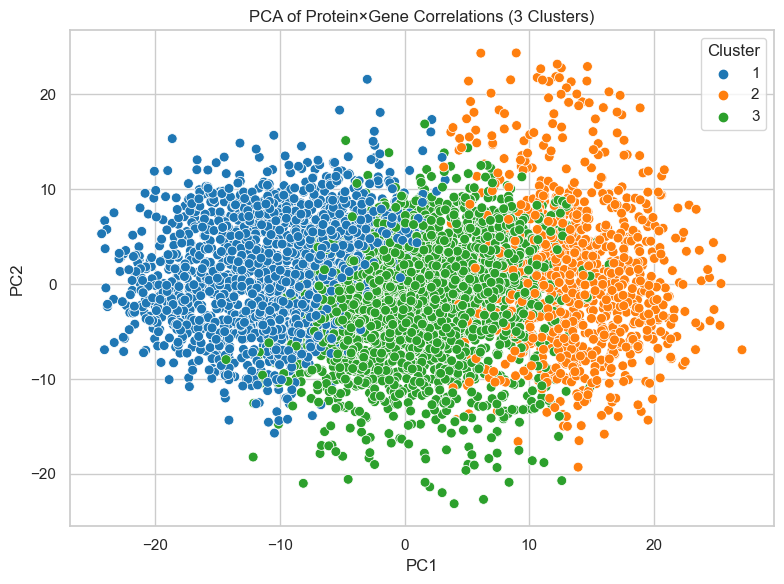

In [32]:
# --- Three clusters: single PCA scatter ---
# Inputs: pearson, clusters (now with 3 cluster labels), df_cluster1, df_cluster2, df_cluster3

# 1) PCA for 3 clusters
pca3 = PCA(n_components=2)
pcs3 = pca3.fit_transform(pearson.fillna(0))
df_pca3 = (
    pd.DataFrame(pcs3, index=pearson.index, columns=['PC1', 'PC2'])
      .join(clusters3.set_index('Protein'))
      .reset_index()
)

# 2) Plot
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df_pca3,
    x='PC1', y='PC2',
    hue='Cluster',
    palette='tab10',
    s=50
)
plt.title('PCA of Protein×Gene Correlations (3 Clusters)')
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()


In [33]:
# --- Configuration ---
thr_pct = 90  # percentile for threshold selection
k_top_genes = 20  # top driver genes

# --- Prepare data ---
clusters = {
    'Cluster 1': df_cluster1,
    'Cluster 2': df_cluster2,
    'Cluster 3': df_cluster3
}

# Flatten and clean values
vals = {}
for name, df in clusters.items():
    v = df.values.flatten()
    v = v[~np.isnan(v)]
    vals[name] = v

# --- Summary Statistics ---
print("=== Summary Statistics ===")
for name, v in vals.items():
    print(f"\n{name}:")
    print(f"  Mean       = {np.mean(v):.4f}")
    print(f"  Std Dev    = {np.std(v, ddof=1):.4f}")
    print(f"  Median     = {np.median(v):.4f}")
    print(f"  Skewness   = {skew(v):.4f}")
    print(f"  Kurtosis   = {kurtosis(v):.4f}")
    for p in [75, 90, 95]:
        print(f"  {p}th pct  = {np.percentile(v, p):.4f}")

# --- Thresholds ---
print("\n=== Cluster-specific Thresholds (|r| at top {}%) ===".format(thr_pct))
thresholds = {}
for name, v in vals.items():
    thr = np.percentile(np.abs(v), thr_pct)
    thresholds[name] = thr
    print(f"{name}: {thr:.4f}")

# --- Cohesion & Separation Metrics ---
print("\n=== Cohesion, Separation, and Silhouette Scores ===")
df_all = pd.concat(list(clusters.values()))
labels = np.concatenate([[i+1]*df.shape[0] for i, df in enumerate(clusters.values())])
X = df_all.values

# Centroids
centroids = {i+1: np.nanmean(df.values, axis=0) for i, df in enumerate(clusters.values())}
global_centroid = np.nanmean(X, axis=0)

# WSS
wss = {}
for i, (name, df) in enumerate(clusters.items(), start=1):
    diffs = df.values - centroids[i]
    wss[i] = np.nansum((diffs**2).sum(axis=1))
    print(f"WSS {name}: {wss[i]:.2f}")

# BSS
bss = sum(df.shape[0] * np.sum((centroids[i+1] - global_centroid)**2) for i, df in enumerate(clusters.values()))
print(f"Between-Cluster SS (BSS): {bss:.2f}")

# Silhouette
sil_vals = silhouette_samples(X, labels, metric='euclidean')
sil_mean = silhouette_score(X, labels, metric='euclidean')
print(f"Mean Silhouette Score: {sil_mean:.4f}")
for i in range(1, 4):
    cluster_sil = sil_vals[labels == i].mean()
    print(f"Cluster {i} Silhouette: {cluster_sil:.4f}")

# --- Cluster Centroids & Top Driver Genes ---
print("\n=== Top Driver Genes per Cluster ===")
genes = df_cluster1.columns  # assuming same columns across clusters
for i in range(1, 4):
    cent = centroids[i]
    top_genes = genes[np.argsort(np.abs(cent))[-k_top_genes:]][::-1]
    print(f"\nTop {k_top_genes} genes for Cluster {i}:")
    print(top_genes.tolist())

=== Summary Statistics ===

Cluster 1:
  Mean       = 0.0073
  Std Dev    = 0.1063
  Median     = 0.0000
  Skewness   = -0.0080
  Kurtosis   = 1.4265
  75th pct  = 0.0000
  90th pct  = 0.1529
  95th pct  = 0.1948

Cluster 2:
  Mean       = -0.0037
  Std Dev    = 0.1312
  Median     = 0.0000
  Skewness   = 0.2125
  Kurtosis   = 1.1019
  75th pct  = 0.0000
  90th pct  = 0.1699
  95th pct  = 0.2293

Cluster 3:
  Mean       = 0.0031
  Std Dev    = 0.0846
  Median     = 0.0000
  Skewness   = 0.1674
  Kurtosis   = 2.6149
  75th pct  = 0.0000
  90th pct  = 0.1224
  95th pct  = 0.1610

=== Cluster-specific Thresholds (|r| at top 90%) ===
Cluster 1: 0.1889
Cluster 2: 0.2254
Cluster 3: 0.1559

=== Cohesion, Separation, and Silhouette Scores ===
WSS Cluster 1: 261167.53
WSS Cluster 2: 169235.97
WSS Cluster 3: 375466.56
Between-Cluster SS (BSS): 384000.58
Mean Silhouette Score: 0.1350
Cluster 1 Silhouette: 0.1693
Cluster 2 Silhouette: 0.1302
Cluster 3 Silhouette: 0.1135

=== Top Driver Genes per C

In [34]:
# Main analysis
# 8. Threshold-based gene retention analysis

# --- Configuration ---
percentiles_to_test = [75, 85, 90, 95, 97]
clusters = {
    'Cluster 1': df_cluster1,
    'Cluster 2': df_cluster2,
    'Cluster 3': df_cluster3,

}
for cluster_name, df_c in clusters.items():
    print(f"\n=== {cluster_name} ===")
    thresholds, retained = corr_utils.compute_gene_retention(df_c, percentiles_to_test)
    for p in percentiles_to_test:
        print(f"Percentile {p}% (Threshold: {thresholds[p]:.4f}): {retained[p]} genes retained")



=== Cluster 1 ===
Percentile 75% (Threshold: 0.1290): 22599 genes retained
Percentile 85% (Threshold: 0.1639): 22405 genes retained
Percentile 90% (Threshold: 0.1889): 21901 genes retained
Percentile 95% (Threshold: 0.2281): 20052 genes retained
Percentile 97% (Threshold: 0.2550): 17978 genes retained

=== Cluster 2 ===
Percentile 75% (Threshold: 0.1541): 22461 genes retained
Percentile 85% (Threshold: 0.1954): 21606 genes retained
Percentile 90% (Threshold: 0.2254): 20101 genes retained
Percentile 95% (Threshold: 0.2729): 16011 genes retained
Percentile 97% (Threshold: 0.3058): 12734 genes retained

=== Cluster 3 ===
Percentile 75% (Threshold: 0.1018): 22607 genes retained
Percentile 85% (Threshold: 0.1346): 22607 genes retained
Percentile 90% (Threshold: 0.1559): 22587 genes retained
Percentile 95% (Threshold: 0.1898): 22205 genes retained
Percentile 97% (Threshold: 0.2135): 21541 genes retained



Cluster 1 critical point:
  Percentile range: 61.22 - 62.24
  Avg genes per protein: 22614.00 → 8537.94
  Drop magnitude: 14076.06
  Correlation threshold value: 0.0000


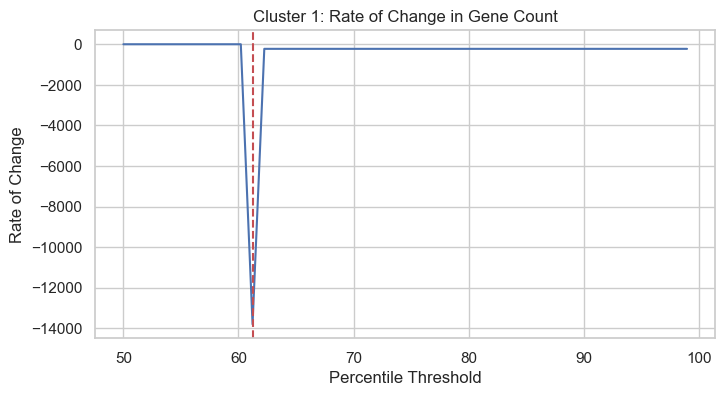


Cluster 2 critical point:
  Percentile range: 53.06 - 54.08
  Avg genes per protein: 22614.00 → 10383.98
  Drop magnitude: 12230.02
  Correlation threshold value: 0.0000


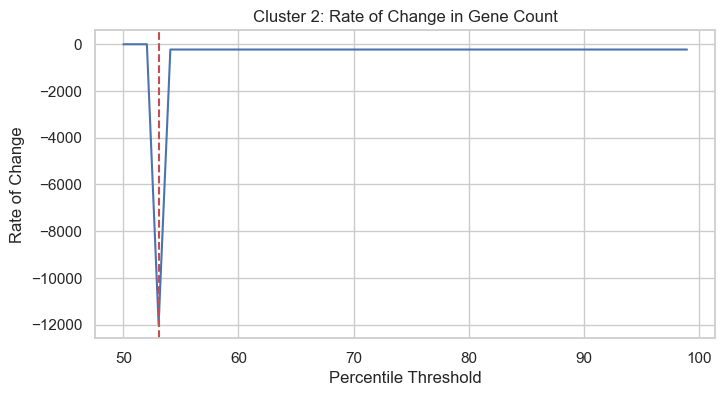


Cluster 3 critical point:
  Percentile range: 69.39 - 70.41
  Avg genes per protein: 22614.00 → 6691.90
  Drop magnitude: 15922.10
  Correlation threshold value: 0.0000


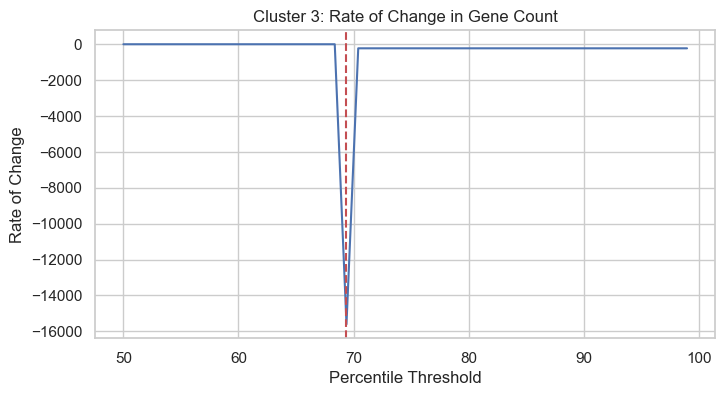

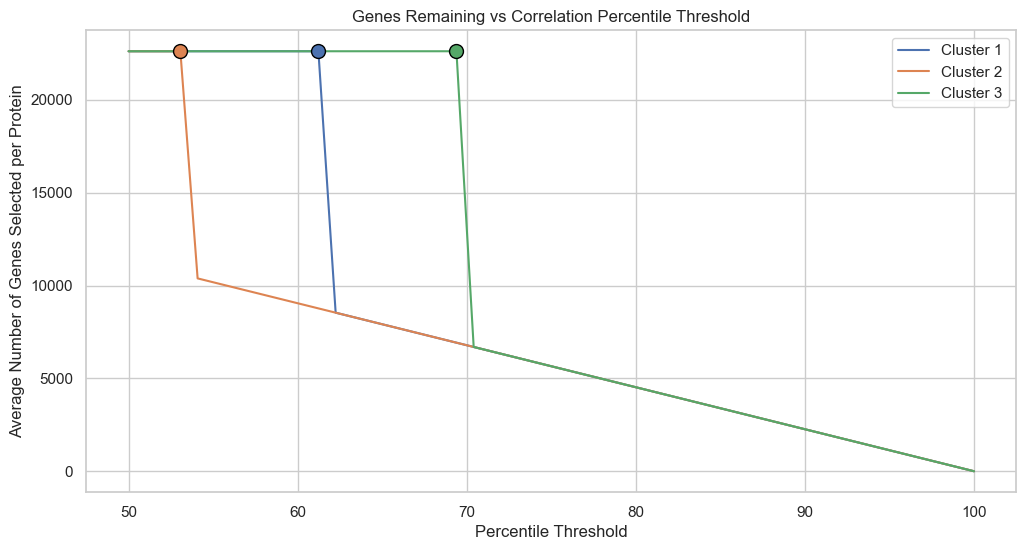

In [35]:
# --- Config ---
percentiles = np.linspace(50, 100, 50)

# Store results
thresholds = {}
gene_counts = {}

# First populate the thresholds and gene_counts dictionaries
for i, (name, df_cluster) in enumerate({"Cluster 1": df_cluster1, "Cluster 2": df_cluster2, "Cluster 3": df_cluster3}.items()):
    vals = df_cluster.values.flatten()
    vals = vals[~np.isnan(vals)]
    
    thr_values = np.percentile(np.abs(vals), percentiles)
    thresholds[name] = thr_values
    
    counts = []
    for thr in thr_values:
        # Calculate average number of genes above threshold per protein (matching graph calculation)
        mask = (np.abs(df_cluster.values) >= thr)
        avg_genes_per_protein = mask.sum(axis=1).mean()
        counts.append(avg_genes_per_protein)
    gene_counts[name] = counts

# Now calculate critical points for each cluster
for name in thresholds.keys():
    # Calculate rate of change (derivative)
    gene_counts_array = np.array(gene_counts[name])
    derivatives = np.diff(gene_counts_array) / np.diff(percentiles)
    
    # Find the index of maximum rate of change (most negative value)
    critical_idx = np.argmin(derivatives)
    
    # Get corresponding percentile and gene counts
    critical_percentile = percentiles[critical_idx]
    critical_percentile_next = percentiles[critical_idx + 1]
    genes_at_critical = gene_counts[name][critical_idx]
    genes_at_next = gene_counts[name][critical_idx + 1]
    
    print(f"\n{name} critical point:")
    print(f"  Percentile range: {critical_percentile:.2f} - {critical_percentile_next:.2f}")
    print(f"  Avg genes per protein: {genes_at_critical:.2f} → {genes_at_next:.2f}")
    print(f"  Drop magnitude: {genes_at_critical - genes_at_next:.2f}")
    
    # Find threshold value at the critical point
    threshold_value = thresholds[name][critical_idx]
    print(f"  Correlation threshold value: {threshold_value:.4f}")
    
    # Optional: plot the derivatives to visualize the critical point
    plt.figure(figsize=(8, 4))
    plt.plot(percentiles[:-1], derivatives)
    plt.axvline(x=critical_percentile, color='r', linestyle='--')
    plt.title(f"{name}: Rate of Change in Gene Count")
    plt.xlabel("Percentile Threshold")
    plt.ylabel("Rate of Change")
    plt.grid(True)
    plt.show()

# Bonus: Plot the gene counts vs percentiles with critical points marked
plt.figure(figsize=(12, 6))
for name in thresholds.keys():
    plt.plot(percentiles, gene_counts[name], label=name)
    
    # Get critical point index and mark it on the plot
    critical_idx = np.argmin(np.diff(gene_counts[name]) / np.diff(percentiles))
    plt.scatter(percentiles[critical_idx], gene_counts[name][critical_idx], 
                marker='o', s=100, edgecolors='black', zorder=5)

plt.xlabel("Percentile Threshold")
plt.ylabel("Average Number of Genes Selected per Protein")
plt.title("Genes Remaining vs Correlation Percentile Threshold")
plt.legend()
plt.grid(True)
plt.show()


Cluster 1 critical point:
  Percentile range: 61.22 - 62.24
  Avg genes per protein: 22614.00 → 8537.94
  Drop magnitude: 14076.06
  Correlation threshold value: 0.0000


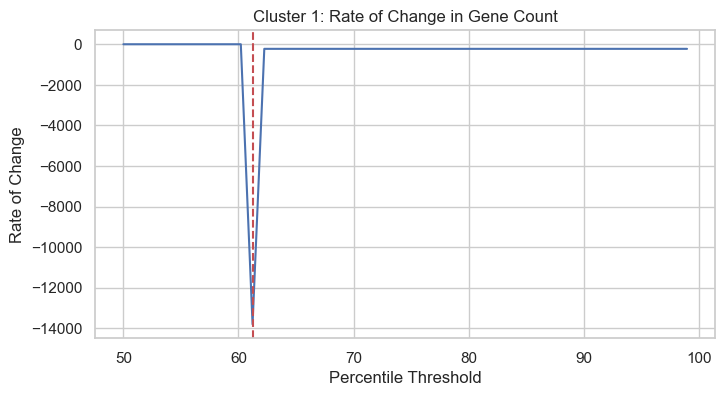


Cluster 2 critical point:
  Percentile range: 53.06 - 54.08
  Avg genes per protein: 22614.00 → 10383.98
  Drop magnitude: 12230.02
  Correlation threshold value: 0.0000


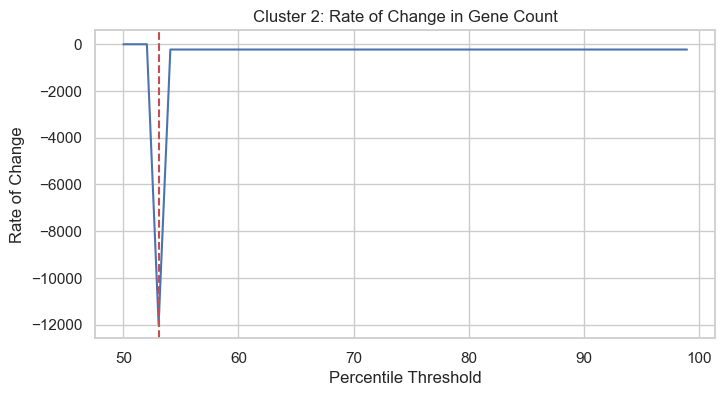


Cluster 3 critical point:
  Percentile range: 69.39 - 70.41
  Avg genes per protein: 22614.00 → 6691.90
  Drop magnitude: 15922.10
  Correlation threshold value: 0.0000


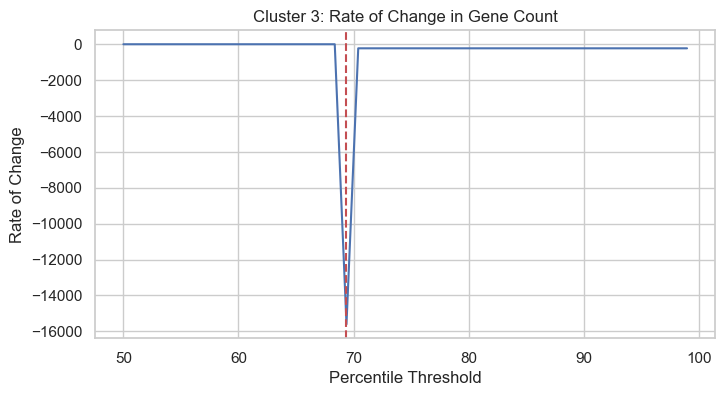

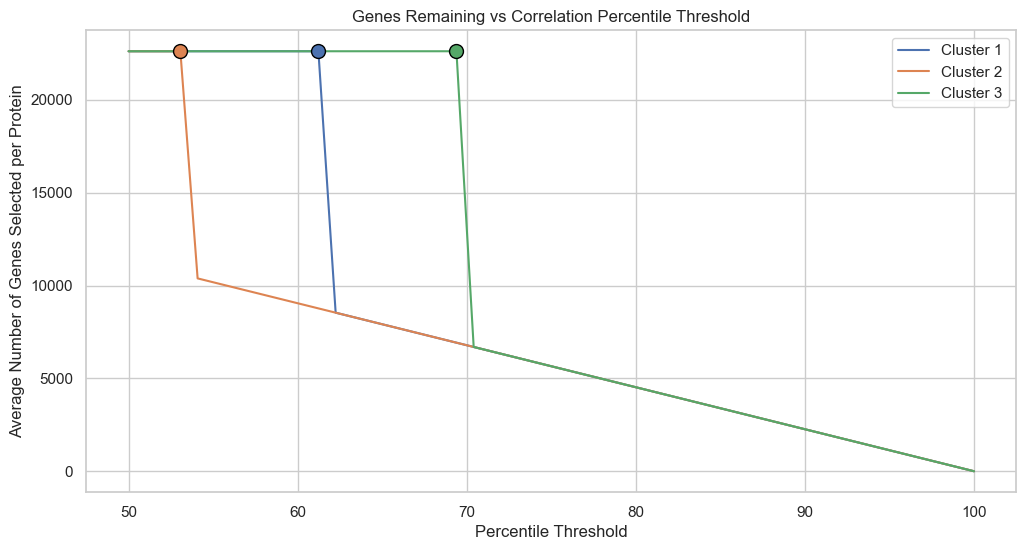

In [36]:
# --- Config ---
percentiles = np.linspace(50, 100, 50)

# Store results
thresholds = {}
gene_counts = {}

# First populate the thresholds and gene_counts dictionaries
for i, (name, df_cluster) in enumerate({"Cluster 1": df_cluster1, "Cluster 2": df_cluster2, "Cluster 3": df_cluster3}.items()):
    vals = df_cluster.values.flatten()
    vals = vals[~np.isnan(vals)]
    
    thr_values = np.percentile(np.abs(vals), percentiles)
    thresholds[name] = thr_values
    
    counts = []
    for thr in thr_values:
        # Calculate average number of genes above threshold per protein (matching graph calculation)
        mask = (np.abs(df_cluster.values) >= thr)
        avg_genes_per_protein = mask.sum(axis=1).mean()
        counts.append(avg_genes_per_protein)
    gene_counts[name] = counts

# Now calculate critical points for each cluster
for name in thresholds.keys():
    # Calculate rate of change (derivative)
    gene_counts_array = np.array(gene_counts[name])
    derivatives = np.diff(gene_counts_array) / np.diff(percentiles)
    
    # Find the index of maximum rate of change (most negative value)
    critical_idx = np.argmin(derivatives)
    
    # Get corresponding percentile and gene counts
    critical_percentile = percentiles[critical_idx]
    critical_percentile_next = percentiles[critical_idx + 1]
    genes_at_critical = gene_counts[name][critical_idx]
    genes_at_next = gene_counts[name][critical_idx + 1]
    
    print(f"\n{name} critical point:")
    print(f"  Percentile range: {critical_percentile:.2f} - {critical_percentile_next:.2f}")
    print(f"  Avg genes per protein: {genes_at_critical:.2f} → {genes_at_next:.2f}")
    print(f"  Drop magnitude: {genes_at_critical - genes_at_next:.2f}")
    
    # Find threshold value at the critical point
    threshold_value = thresholds[name][critical_idx]
    print(f"  Correlation threshold value: {threshold_value:.4f}")
    
    # Optional: plot the derivatives to visualize the critical point
    plt.figure(figsize=(8, 4))
    plt.plot(percentiles[:-1], derivatives)
    plt.axvline(x=critical_percentile, color='r', linestyle='--')
    plt.title(f"{name}: Rate of Change in Gene Count")
    plt.xlabel("Percentile Threshold")
    plt.ylabel("Rate of Change")
    plt.grid(True)
    plt.show()

# Bonus: Plot the gene counts vs percentiles with critical points marked
plt.figure(figsize=(12, 6))
for name in thresholds.keys():
    plt.plot(percentiles, gene_counts[name], label=name)
    
    # Get critical point index and mark it on the plot
    critical_idx = np.argmin(np.diff(gene_counts[name]) / np.diff(percentiles))
    plt.scatter(percentiles[critical_idx], gene_counts[name][critical_idx], 
                marker='o', s=100, edgecolors='black', zorder=5)

plt.xlabel("Percentile Threshold")
plt.ylabel("Average Number of Genes Selected per Protein")
plt.title("Genes Remaining vs Correlation Percentile Threshold")
plt.legend()
plt.grid(True)
plt.show()

Gene correlated with at least a protein